# 10.2 — The live 2026-27 Most Improved race

**Re-run this notebook whenever you want an update.** It downloads the newest game logs, rebuilds the race and redraws the charts.

**Question.** Who leads the 2026-27 Most Improved Player (MIP) race so far, and how much should we believe it at this point of the season?

**Decisions**
- **Same comparison as notebook 10:** this season's per-game numbers so far against each player's baseline season (most recent season with at least 33% of the games).
- **A model for each point of the season.** The model is trained on past seasons cut at the **same number of days after opening night**, so it has learned how much a few days of games say about the eventual winner. Season-long stats (usage, start rate, defensive rating) are left out, as in notebook 10's mid-season race.
- **Inputs:** changes in points, rebounds, assists, steals, blocks, minutes, game score and true shooting; relative change in points and game score; team win % change; age; second-year flag. Penalty λ = 3.
- **Candidates:** at least one previous NBA season, a baseline season, and at least half of his team's games so far. Previous winners excluded (as in 10.1).
- **Age** is rolled forward from each player's latest season in our table, so players who missed 2025-26 (Tyrese Haliburton, Damian Lillard) still get one.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nba_api.stats.endpoints import leaguegamelog
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs, mip_candidates
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT, fetch

warnings.filterwarnings("ignore")
apply_style()
LIVE, LIVE_START, L2 = "2026-27", 2026, 3.0
EARLY = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR

fetch(leaguegamelog.LeagueGameLog, refresh=True, season=LIVE, player_or_team_abbreviation="P", season_type_all_star="Regular Season")
games, _, _ = build_game_table(load_game_logs(GAMELOG_SEASONS + [LIVE]))
games["day"] = (games["game_date"] - games.groupby("season")["game_date"].transform("min")).dt.days
live_games = games[games["season"] == LIVE]
DAY_NOW = int(live_games["day"].max())
team_games = live_games.groupby("team_id")["game_id"].nunique()
print(f"{LIVE}: {live_games['game_id'].nunique()} games through {live_games['game_date'].max():%d %b %Y} "
      f"(day {DAY_NOW} after opening night); teams have played {team_games.min()}–{team_games.max()} games")

2026-27: 16 games through 22 Oct 2026 (day 2 after opening night); teams have played 1–2 games


In [2]:
# player table with a 2026-27 row: age and experience rolled forward from each player's latest season
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
latest = ps[ps["season_start"] < LIVE_START].sort_values("season_start").groupby("player_id").tail(1)
gap = LIVE_START - latest["season_start"]
ps_live = pd.concat([ps, latest[["player_id"]].assign(season_start=LIVE_START, age=latest["age"] + gap, exp=latest["exp"] + gap)], ignore_index=True)

first_win = {pid: int(s[:4]) for s, pid in sorted(MIP_WINNERS.items(), reverse=True)}

def race(day):
    """Eligible candidates in every season, using only games up to `day` days after that season's opener."""
    c = mip_candidates(games[games["day"] <= day], ps_live, min_prior_seasons=1, season_stats=False)
    c["second_year"] = (c["prior_seasons"] == 1).astype(float)
    c["mip"] = [MIP_WINNERS.get(s) == p for s, p in zip(c["season"], c["player_id"])]
    c["previous_winner"] = [first_win.get(p, 9999) < y for p, y in zip(c["player_id"], c["season_start"])]
    return c[c["eligible"] & ~c["previous_winner"] & (c["season_start"] >= 2011)].reset_index(drop=True)

now = race(DAY_NOW)
print("live candidates:", (now["season"] == LIVE).sum(), "| missing age:", now.loc[now["season"] == LIVE, "age"].isna().sum())

live candidates: 292 | missing age: 0


## 10.2A — How much can this many days tell us?

Before looking at the leaders: in past seasons, where did the **eventual winner** rank at the same point of the season? Each season is predicted by a model trained on the other seasons, cut at the same day.

In [3]:
def winner_ranks(day):
    c = now if day == DAY_NOW else race(day)
    h = c[c["season"] != LIVE]
    out = {}
    for s in sorted(h["season"].unique()):
        te = h[h["season"] == s]
        if not te["mip"].any():
            out[s] = np.nan          # the eventual winner had not yet played enough to be a candidate
            continue
        p = ChoiceModel(EARLY, L2).fit(h[h["season"] != s]).predict_proba(te)
        out[s] = p.rank(ascending=False, method="min")[te["mip"]].iloc[0]
    return pd.Series(out)

DAYS = sorted({DAY_NOW, 7, 14, 30, 60, 90, 120})
ranks = pd.DataFrame({d: winner_ranks(d) for d in DAYS})
curve = pd.DataFrame({"winner #1": (ranks == 1).sum(), "winner in top 3": (ranks <= 3).sum(), "winner in top 7": (ranks <= 7).sum(),
                      "winner in top 20": (ranks <= 20).sum(), "median winner rank": ranks.median()}).T
curve.columns = [f"day {d}" for d in DAYS]
print(f"out of {len(ranks)} past seasons (2011-12 → 2025-26)")
curve.round(1)

out of 15 past seasons (2011-12 → 2025-26)


,day 2,day 7,day 14,day 30,day 60,day 90,day 120
winner #1,0.0,3.0,1.0,3.0,5.0,7.0,7.0
winner in top 3,1.0,4.0,6.0,7.0,9.0,10.0,10.0
winner in top 7,4.0,6.0,7.0,11.0,11.0,11.0,11.0
winner in top 20,8.0,8.0,11.0,12.0,13.0,14.0,15.0
median winner rank,19.0,11.0,7.0,4.0,3.0,2.0,2.0


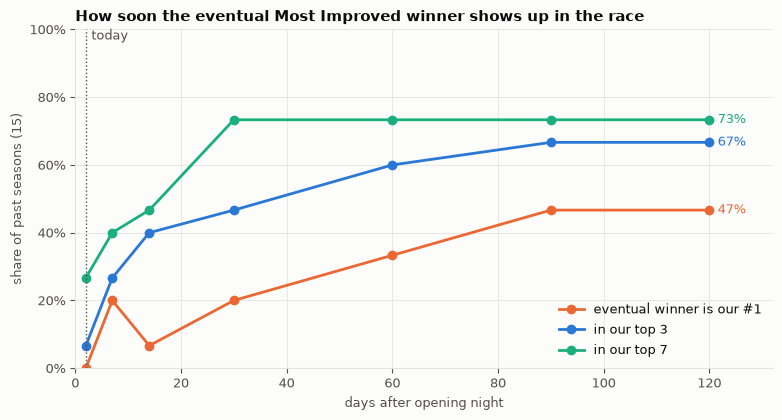

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.4))
n = len(ranks)
for (label, k), col in zip([("eventual winner is our #1", 1), ("in our top 3", 3), ("in our top 7", 7)], [ORANGE, BLUE, SERIES[2]]):
    share = [(ranks[d] <= k).sum() / n for d in DAYS]
    ax.plot(DAYS, share, marker="o", color=col, label=label)
    ax.annotate(f"{share[-1]:.0%}", (DAYS[-1], share[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=col)
ax.axvline(DAY_NOW, color=INK2, linewidth=1, linestyle=":")
ax.annotate("today", (DAY_NOW, 0.97), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(0, DAYS[-1] + 12)
ax.set_xlabel("days after opening night"); ax.set_ylabel(f"share of past seasons ({n})")
ax.legend(frameon=False, loc="lower right")
ax.set_title("How soon the eventual Most Improved winner shows up in the race", loc="left")
fig.savefig(FIG_DIR / "10_2_race_by_day.png", dpi=150, bbox_inches="tight")

### 10.2A findings

- **After two days (one game for most teams), the race says very little.** The eventual winner was in our top 7 in 4 of 15 past seasons, in the top 3 once, and never #1. Median rank 19.
- **That is no better than the preseason prediction** in notebook 10.1 (winner in its top 7 in 4 of 14 seasons). One game adds about as much as a preseason.
- **It sharpens quickly.** By day 14 (about 6–7 games) the winner is in the top 7 in 7 of 15 seasons; by **day 30 (about 14 games) in 11 of 15, median rank 4.** After that the top 7 stops improving; what changes is the order at the top (#1 in 7 of 15 by day 90).
- **Rule of thumb:** treat the race as noise for the first two weeks, as a real shortlist after a month, and as a real ranking from about the All-Star break.

## 10.2B — The race today

In [5]:
hist, T = now[now["season"] != LIVE], now[now["season"] == LIVE].copy()
model = ChoiceModel(EARLY, L2).fit(hist)
T["chance"] = model.predict_proba(T)
T = T.sort_values("chance", ascending=False).reset_index(drop=True)
T["rank"] = np.arange(1, len(T) + 1)

NICE = {"ppg_delta": "points", "rpg_delta": "rebounds", "apg_delta": "assists", "spg_delta": "steals", "bpg_delta": "blocks",
        "mpg_delta": "minutes", "game_score_delta": "game score", "ts_delta": "shooting efficiency", "ppg_rel": "points (relative)",
        "game_score_rel": "game score (relative)", "team_win_delta": "team winning more", "age": "age", "second_year": "second-year discount"}
Z = pd.DataFrame(model._design(T), index=T.index, columns=EARLY)
contrib = ((Z - Z.mean()) * model.coef_).rename(columns=NICE)
T["why"] = [" + ".join(contrib.loc[i].nlargest(2).index) for i in T.index]
print("weights:", model.coefficients().rename(NICE).round(2).sort_values(ascending=False).to_dict())
cols = {"rank": "rank", "player_name": "player", "team": "team", "chance": "chance", "games": "games", "ppg": "points", "base_ppg": "points last season",
        "game_score": "game score", "base_game_score": "game score last season", "mpg": "minutes", "base_mpg": "minutes last season", "age": "age", "why": "main reasons"}
T.head(10)[list(cols)].rename(columns=cols).style.format({"chance": "{:.1%}"}, precision=1).hide(axis="index")

weights: {'points': 0.64, 'assists': 0.43, 'points (relative)': 0.32, 'team winning more': 0.25, 'rebounds': 0.08, 'game score (relative)': 0.07, 'steals': 0.05, 'blocks': 0.04, 'game score': 0.02, 'minutes': -0.06, 'shooting efficiency': -0.28, 'second-year discount': -0.65, 'age': -0.83}


rank,player,team,chance,games,points,points last season,game score,game score last season,minutes,minutes last season,age,main reasons
1,Ty Jerome,MEM,19.8%,1,45.0,12.5,38.7,10.7,32.0,19.9,29.6,points + points (relative)
2,Yves Missi,NOP,5.9%,1,13.0,5.7,22.8,6.9,30.0,19.6,22.7,assists + points
3,Jabari Smith Jr.,HOU,3.4%,1,30.0,15.8,24.9,11.9,36.0,35.1,23.7,points + age
4,Paolo Banchero,ORL,3.3%,1,35.0,22.2,32.7,17.0,41.0,34.7,24.2,points + assists
5,Anthony Edwards,MIN,2.6%,1,45.0,28.8,34.1,20.7,33.0,35.0,25.5,points + age
6,Ja'Kobe Walter,TOR,2.4%,1,10.0,7.5,9.7,6.1,23.0,20.4,22.4,age + assists
7,Walker Kessler,LAL,2.3%,1,26.0,11.1,24.8,14.0,30.0,30.1,25.5,points + points (relative)
8,Moussa Diabaté,CHA,2.2%,1,17.0,7.9,18.0,10.3,34.0,26.0,25.0,points + points (relative)
9,Naz Reid,CHA,2.2%,1,20.0,13.6,15.9,10.5,33.0,26.1,27.4,assists + points
10,Tyler Herro,MIL,1.4%,1,24.0,20.5,16.4,15.2,32.0,31.2,27.0,assists + points


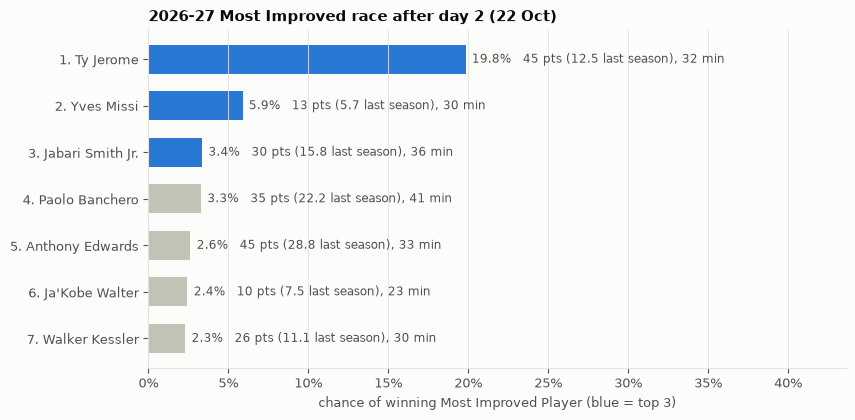

In [6]:
top = T.head(7).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(top))
ax.barh(y, top["chance"], color=[BLUE if r <= 3 else MUTED for r in top["rank"]], height=0.62)
for yi, (_, r) in zip(y, top.iterrows()):
    ax.text(r["chance"] + top["chance"].max() * 0.02, yi, f"{r['chance']:.1%}   {r['ppg']:.0f} pts ({r['base_ppg']:.1f} last season), {r['mpg']:.0f} min",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"{r['rank']}. {r['player_name']}" for _, r in top.iterrows()], fontsize=9.5)
ax.set_xlim(0, top["chance"].max() * 2.2); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.set_xlabel("chance of winning Most Improved Player (blue = top 3)")
ax.set_title(f"{LIVE} Most Improved race after day {DAY_NOW} ({live_games['game_date'].max():%d %b})", loc="left")
fig.savefig(FIG_DIR / "10_2_race_today.png", dpi=150, bbox_inches="tight")

In [7]:
# how our preseason top 7 (notebook 10.1, preseason through 12 Oct) has started
PRESEASON_TOP7 = ["Reed Sheppard", "Stephon Castle", "Ty Jerome", "Rui Hachimura", "Amen Thompson", "Leonard Miller", "Tristan da Silva"]
rows = []
for i, name in enumerate(PRESEASON_TOP7, 1):
    r = T[T["player_name"] == name]
    played = live_games[live_games["player_name"] == name]
    rows.append({"preseason rank": i, "player": name, "games": len(played),
                 "points": played["pts"].mean() if len(played) else np.nan,
                 "points last season": r["base_ppg"].iloc[0] if len(r) else np.nan,
                 "race rank now": int(r["rank"].iloc[0]) if len(r) else None, "chance now": f"{r['chance'].iloc[0]:.1%}" if len(r) else "not yet a candidate"})
pd.DataFrame(rows).set_index("preseason rank").round(1)

,player,games,points,points last season,race rank now,chance now
preseason rank,,,,,,
1,Reed Sheppard,1,3.0,13.5,85,0.3%
2,Stephon Castle,1,24.0,16.7,94,0.2%
3,Ty Jerome,1,45.0,12.5,1,19.8%
4,Rui Hachimura,1,10.0,11.5,44,0.5%
5,Amen Thompson,1,16.0,18.3,50,0.4%
6,Leonard Miller,1,4.0,7.8,65,0.3%
7,Tristan da Silva,1,14.0,9.9,35,0.5%


### 10.2B findings (after day 2, 22 October)

- **Ty Jerome leads clearly (about 20%).** He scored 45 points in 32 minutes against 12.5 points a game last season. He was #3 in our preseason top 7, and the only one of those seven to start hot. Age (29.6) is the main thing holding his chance down.
- **Behind him the field is wide open:** Yves Missi (about 6%), then Jabari Smith Jr., Paolo Banchero, Anthony Edwards, Ja'Kobe Walter and Walker Kessler, each 2–3%.
- **Our other preseason picks had quiet openers:** Reed Sheppard 3 points (85th now), Stephon Castle 24 points but from a higher base (94th).
- **What the model rewards this early:** a points jump (+0.64 per SD) and an assists jump (+0.43); it marks down age (−0.83) and second-year players (−0.65), as in notebook 10.

**Open decision (yours): the 22-point rule from 10.1.** It is not applied here, so established scorers can appear (Anthony Edwards, last season 28.8). Banchero sits right on that line (22.2). Applying it would make 10.1 and 10.2 consistent.

**Re-run** this notebook at any time; the first cell downloads the latest games.